# **Tarea 2: Implementación de Metaheurística (Algoritmo Genético)**

### 1. Lectura de Instancias (.txt), Evaluación de Makespan y Generación de Individuos
En este primer bloque se definen las tres funciones base que conectan los datos de los archivos con el Algoritmo Genético:
* **`cargar_instancia(filepath)`:** Lee el archivo `.txt` de la instancia (fácil, media o difícil). Extrae de la primera línea la cantidad de trabajos ($N$) y máquinas ($M$), y luego construye la matriz de rutas y tiempos de procesamiento (`matriz_tm`).
* **`makespan(matriz_tm, orden, num_maquinas)`:** Es nuestra función objetivo $f(s)$. Decodifica una secuencia de operaciones de izquierda a derecha, asignando cada operación a su máquina en el tiempo más temprano posible (respetando que la máquina esté libre y que la etapa anterior del mismo trabajo haya terminado). Retorna el tiempo en que termina el último trabajo ($C_{\max}$).
* **`generar_individuo_aleatorio(num_trabajos, num_maquinas)`:** A partir del $N$ y $M$ leídos del archivo, construye una solución inicial válida (genotipo). Crea una lista donde el ID de cada trabajo aparece repetido exactamente $M$ veces y luego la desordena al azar (`random.shuffle`). Se usa en el paso inicial del algoritmo para crear los 50 individuos de la población de partida.

In [ ]:
import os
import time
import random
import statistics
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

def cargar_instancia(filepath):
    """Lee cualquier instancia JSP (.txt) detectando dinámicamente filas (N) y columnas (M)."""
    with open(filepath, 'r') as f:
        lines = [line.strip() for line in f if line.strip() and not line.startswith('#')]

    num_trabajos, num_maquinas = map(int, lines[0].split())
    matriz_tm = []

    for line in lines[1:num_trabajos + 1]:
        partes = list(map(int, line.split()))
        trabajo = [(partes[i], partes[i+1]) for i in range(0, len(partes), 2)]
        matriz_tm.append(trabajo)

    return matriz_tm, num_trabajos, num_maquinas

@njit
def _makespan_njit(matriz_np, orden_np, num_maquinas):
    """Núcleo compilado en código máquina (Numba JIT) para evaluar el makespan a máxima velocidad."""
    cantidad_muebles = matriz_np.shape[0]
    t_maquinas = np.zeros(num_maquinas, dtype=np.int64)
    t_muebles = np.zeros(cantidad_muebles, dtype=np.int64)
    proceso_muebles = np.zeros(cantidad_muebles, dtype=np.int64)

    for i in range(len(orden_np)):
        mueble = orden_np[i]
        etapa = proceso_muebles[mueble]
        proceso_muebles[mueble] = etapa + 1

        maquina = matriz_np[mueble, etapa, 0]
        t_etapa = matriz_np[mueble, etapa, 1]

        tm = t_maquinas[maquina]
        tj = t_muebles[mueble]
        t_fin = (tm if tm > tj else tj) + t_etapa

        t_maquinas[maquina] = t_fin
        t_muebles[mueble] = t_fin

    max_t = 0
    for j in range(cantidad_muebles):
        if t_muebles[j] > max_t:
            max_t = t_muebles[j]
    return max_t

def makespan(matriz_tm, orden, num_maquinas):
    """Calcula el makespan aceptando tanto listas de Python como arreglos NumPy."""
    if not isinstance(matriz_tm, np.ndarray):
        matriz_tm = np.array(matriz_tm, dtype=np.int64)
    orden_np = np.array(orden, dtype=np.int64)
    return int(_makespan_njit(matriz_tm, orden_np, num_maquinas))

def generar_individuo_aleatorio(num_trabajos, num_maquinas):
    """Genera un genotipo válido con cada trabajo repetido exactamente M veces."""
    individuo = []
    for i in range(num_trabajos):
        individuo.extend([i] * num_maquinas)
    random.shuffle(individuo)
    return individuo

# Pre-compilación rápida en vacío para dejar listo Numba
_ = _makespan_njit(np.zeros((2, 2, 2), dtype=np.int64), np.array([0, 1, 0, 1], dtype=np.int64), 2)



---


### 2. Operadores Genéticos: Selección por Ruleta, Cruzamiento POX y Mutación Swap
El código a continuación implementa los tres operadores evolutivos que transforman la población en cada generación:

1. **`seleccion_ruleta(poblacion, k=2)` (Selección de Padres):**
   El método de la ruleta entrega mayor probabilidad de ser elegido a quien tenga un puntaje mayor. Sin embargo, en el JSP buscamos **minimizar** el *makespan* (un costo menor es mejor). Para evitar que la ruleta premie a las peores soluciones (las más lentas), invertimos los costos con la fórmula:
   $$\hat{f}(s) = \min\_fitness + \max\_fitness - f(s)$$
   Donde:
   * **$f(s)$:** Es el *makespan* de la solución actual $s$ que estamos evaluando.
   * **$\min\_fitness$:** Es el **mejor** (menor) *makespan* encontrado dentro de la población actual.
   * **$\max\_fitness$:** Es el **peor** (mayor) *makespan* dentro de la población actual.
   * **$\hat{f}(s)$ (Peso en la ruleta):** Es el puntaje invertido. Gracias a esta operación, el individuo más rápido ($f(s) = \min\_fitness$) queda con el peso más grande ($\max\_fitness$), ocupando la porción más ancha de la ruleta, mientras que el peor individuo conserva un peso positivo ($\min\_fitness$) para no anular su probabilidad a cero.

2. **`cruzamiento_pox(padre1, padre2, num_trabajos)` (*Precedence Operation Crossover*):**
   Un corte simple de listas arruinaría la validez de los hijos (habría trabajos con más o menos de $M$ operaciones). El operador **POX** soluciona esto dividiendo los trabajos al azar en dos grupos disjuntos ($J_1$ y $J_2$):
   * El **Hijo 1** hereda las operaciones del grupo $J_1$ desde el **Padre 1** exactamente en las mismas casillas, y rellena las casillas vacías de izquierda a derecha con las operaciones del grupo $J_2$ manteniendo el orden en que aparecen en el **Padre 2** (y viceversa para el Hijo 2). Así se conserva siempre la factibilidad sin requerir algoritmos de reparación.

3. **`mutacion_swap(individuo, prob_mutacion=0.15)` (Operador de Movimiento *Swap*):**
   Reutiliza el movimiento del Taller 6: genera un número aleatorio entre $0$ y $1$; si es menor a `0.15` (15% de probabilidad), elige dos posiciones al azar que correspondan a **trabajos distintos** e intercambia sus lugares. Esto introduce cambios puntuales para escapar de óptimos locales sin destruir los bloques eficientes heredados en el cruzamiento.

In [ ]:
def calcular_pesos_ruleta(costos):
    """
    Invierte el fitness para minimización amplificando la ventaja de los mejores individuos.
    Así evitamos que costos grandes (ej. 3100 vs 3200) tengan casi el mismo peso en la ruleta.
    """
    max_fitness = max(costos)
    min_fitness = min(costos)
    if max_fitness == min_fitness:
        return [1.0] * len(costos)
    # Amplificamos la diferencia respecto al peor costo de la generación
    return [((max_fitness - c) + 1.0) ** 2 for c in costos]

def seleccion_ruleta(poblacion, k=2):
    """Selecciona k padres mediante ruleta proporcional al fitness invertido."""
    costos = [ind[0] for ind in poblacion]
    pesos = calcular_pesos_ruleta(costos)
    seleccionados = random.choices(poblacion, weights=pesos, k=k)
    return [ind[1] for ind in seleccionados]

def cruzamiento_pox(padre1, padre2, num_trabajos):
    """Aplica Precedence Operation Crossover (POX) generando dos hijos factibles."""
    trabajos = list(range(num_trabajos))
    random.shuffle(trabajos)
    corte = random.randint(1, max(1, num_trabajos - 1))
    j1 = set(trabajos[:corte])

    n = len(padre1)
    hijo1 = [-1] * n
    hijo2 = [-1] * n

    for idx in range(n):
        p1_val = padre1[idx]
        p2_val = padre2[idx]
        if p1_val in j1:
            hijo1[idx] = p1_val
        if p2_val in j1:
            hijo2[idx] = p2_val

    iter_p2 = (op for op in padre2 if op not in j1)
    iter_p1 = (op for op in padre1 if op not in j1)

    for idx in range(n):
        if hijo1[idx] == -1:
            hijo1[idx] = next(iter_p2)
        if hijo2[idx] == -1:
            hijo2[idx] = next(iter_p1)

    return hijo1, hijo2

def mutacion_swap(individuo, prob_mutacion=0.20):
    """
    Aplica el operador Swap. En cromosomas largos (>100 operaciones), realiza hasta 2 intercambios
    para que la perturbación sea proporcional al tamaño de la instancia.
    """
    mutado = list(individuo)
    if random.random() < prob_mutacion:
        n = len(mutado)
        num_swaps = 2 if n >= 150 else 1
        for _ in range(num_swaps):
            for _ in range(10):
                idx1, idx2 = random.sample(range(n), 2)
                if mutado[idx1] != mutado[idx2]:
                    mutado[idx1], mutado[idx2] = mutado[idx2], mutado[idx1]
                    break
    return mutado



---


### 3. Ciclo Evolutivo del Algoritmo Genético ($\mu + \lambda$ con Elitismo Parcial)
La función `algoritmo_genetico_jsp` conecta todos los componentes anteriores y ejecuta el ciclo evolutivo bajo los parámetros definidos:
* **Población inicial ($\mu = 50$):** Se crean y evalúan 50 secuencias aleatorias iniciales (consumiendo las primeras 50 evaluaciones).
* **Generación de descendencia ($\lambda = 50$):** En cada generación se repite el proceso de seleccionar 2 padres por ruleta, cruzarlos con POX y mutar a los 2 hijos con *Swap* hasta reunir 50 hijos nuevos.
* **Selección de sobrevivientes ($\mu + \lambda$):** Se unen los 50 padres con los 50 hijos (100 candidatos en total) y se ordenan de menor a mayor *makespan*.
  * **Elitismo parcial ($e = 10\%$):** Los 5 mejores individuos ($50 \times 0.10 = 5$) pasan directamente a la siguiente generación sin competir, asegurando que nunca se pierda la mejor solución alcanzada.
  * **Ruleta para el 90% restante:** Los 45 cupos restantes se eligen girando la ruleta entre los 95 individuos sobrantes para mantener diversidad en la población.
* **Criterio de término (`max_gen = 200`):** El bucle se repite exactamente por 200 generaciones, realizando un presupuesto fijo de $50 + (200 \times 50) = 10.050$ evaluaciones de la función objetivo por corrida.

In [ ]:
def algoritmo_genetico_jsp(matriz_np, num_trabajos, num_maquinas,
                           mu=50, lam=50, elitismo=0.10,
                           prob_mutacion=0.20, max_gen=200):
    t_inicio = time.time()
    evaluaciones = 0

    # 1. Generar y evaluar población inicial G de tamaño mu
    poblacion = []
    for _ in range(mu):
        genotipo = generar_individuo_aleatorio(num_trabajos, num_maquinas)
        costo = int(_makespan_njit(matriz_np, np.array(genotipo, dtype=np.int64), num_maquinas))
        evaluaciones += 1
        poblacion.append((costo, genotipo))

    mejor_historico = min(poblacion, key=lambda x: x[0])
    num_elites = max(1, int(mu * elitismo))

    # 2. Ciclo generacional
    for gen in range(max_gen):
        hijos = []

        while len(hijos) < lam:
            p1, p2 = seleccion_ruleta(poblacion, k=2)
            h1, h2 = cruzamiento_pox(p1, p2, num_trabajos)

            for h in (h1, h2):
                if len(hijos) < lam:
                    h_mut = mutacion_swap(h, prob_mutacion)
                    c_mut = int(_makespan_njit(matriz_np, np.array(h_mut, dtype=np.int64), num_maquinas))
                    evaluaciones += 1
                    hijos.append((c_mut, h_mut))

        # 3. Unir padres e hijos (mu + lambda) y ordenar por mejor fitness
        combinados = poblacion + hijos
        combinados.sort(key=lambda x: x[0])

        if combinados[0][0] < mejor_historico[0]:
            mejor_historico = combinados[0]

        # 4. Selección de sobrevivientes: Top e% de élites únicos + Ruleta
        nueva_poblacion = []
        vistos = set()
        resto_candidatos = []

        for ind in combinados:
            clave = tuple(ind[1])
            if len(nueva_poblacion) < num_elites and clave not in vistos:
                nueva_poblacion.append(ind)
                vistos.add(clave)
            else:
                resto_candidatos.append(ind)

        cupos_restantes = mu - len(nueva_poblacion)
        costos_r = [ind[0] for ind in resto_candidatos]
        pesos_r = calcular_pesos_ruleta(costos_r)

        elegidos_ruleta = random.choices(resto_candidatos, weights=pesos_r, k=cupos_restantes)
        nueva_poblacion.extend(elegidos_ruleta)
        poblacion = nueva_poblacion

    tiempo_total = time.time() - t_inicio
    return mejor_historico[1], mejor_historico[0], evaluaciones, tiempo_total



---

### 4. Experimentación: 10 Ejecuciones Independientes por Instancia y Estadísticas
Como el Algoritmo Genético es un método estocástico (usa probabilidades en la población inicial, ruleta, cruzamiento POX y mutación), una sola corrida no basta para evaluar su desempeño.

En el siguiente bloque se ejecuta el algoritmo **10 veces con distintas semillas aleatorias (`random.seed`)** sobre cada archivo de instancia cargado. Para cada instancia se imprime la tabla de las 10 corridas y se calcula automáticamente:
* Los **10 valores de la función de evaluación** ($C_{\max}$).
* El **mejor *makespan* encontrado** y su secuencia de operaciones correspondiente (genotipo).
* La **media** y **desviación estándar** de los 10 resultados, junto con el tiempo promedio de cómputo.

In [ ]:
ARCHIVOS_INSTANCIAS = ["01_facil.txt", "02_medio.txt", "03_dificil.txt"]
NUM_EJECUCIONES = 10
resultados_base_boxplot = {}

for archivo in ARCHIVOS_INSTANCIAS:
    if not os.path.exists(archivo):
        print(f"⚠️ Archivo '{archivo}' no encontrado en el entorno. Subir para evaluar.\n")
        continue

    matriz_tm, n_trab, n_maq = cargar_instancia(archivo)
    matriz_np = np.array(matriz_tm, dtype=np.int64)

    print("=" * 80)
    print(f"INSTANCIA: '{archivo}' | Tamaño: {n_trab} Trabajos x {n_maq} Máquinas ({n_trab * n_maq} ops)")
    print("=" * 80)
    print(f"{'Corrida':<12} | {'Makespan (C_max)':<18} | {'Evaluaciones':<15} | {'Tiempo (s)':<12}")
    print("-" * 80)

    costos_instancia = []
    tiempos_instancia = []
    mejor_global_instancia = (float('inf'), None)

    for corrida in range(1, NUM_EJECUCIONES + 1):
        random.seed(100 + corrida)

        secuencia, costo, evals, t_ejec = algoritmo_genetico_jsp(
            matriz_np, n_trab, n_maq,
            mu=50, lam=50, elitismo=0.10, prob_mutacion=0.20, max_gen=200
        )

        costos_instancia.append(costo)
        tiempos_instancia.append(t_ejec)

        if costo < mejor_global_instancia[0]:
            mejor_global_instancia = (costo, secuencia)

        print(f"Ejecución {corrida:<2} | {costo:<18} | {evals:<15} | {t_ejec:.4f} s")

    resultados_base_boxplot[archivo] = costos_instancia
    media_c = statistics.mean(costos_instancia)
    desv_c = statistics.stdev(costos_instancia) if len(costos_instancia) > 1 else 0.0
    media_t = statistics.mean(tiempos_instancia)

    print("-" * 80)
    print(f"📊 RESUMEN ESTADÍSTICO ({NUM_EJECUCIONES} corridas) - '{archivo}':")
    print(f"• 10 Valores de Fitness : {costos_instancia}")
    print(f"• Mejor Makespan (Óptimo): {mejor_global_instancia[0]} min")
    print(f"• Media de Makespan      : {media_c:.2f} min")
    print(f"• Desviación Estándar    : {desv_c:.2f} min")
    print(f"• Tiempo Promedio        : {media_t:.4f} s")
    print(f"• Mejor Secuencia (Genotipo): {mejor_global_instancia[1]}\n")

INSTANCIA: '01_facil.txt' | Tamaño: 6 Trabajos x 6 Máquinas (36 ops)
Corrida      | Makespan (C_max)   | Evaluaciones    | Tiempo (s)  
--------------------------------------------------------------------------------
Ejecución 1  | 59                 | 10050           | 0.2573 s
Ejecución 2  | 55                 | 10050           | 0.2252 s
Ejecución 3  | 55                 | 10050           | 0.2330 s
Ejecución 4  | 58                 | 10050           | 0.2274 s
Ejecución 5  | 55                 | 10050           | 0.2465 s
Ejecución 6  | 57                 | 10050           | 0.3870 s
Ejecución 7  | 55                 | 10050           | 0.3808 s
Ejecución 8  | 55                 | 10050           | 0.3995 s
Ejecución 9  | 57                 | 10050           | 0.4469 s
Ejecución 10 | 59                 | 10050           | 0.4126 s
--------------------------------------------------------------------------------
📊 RESUMEN ESTADÍSTICO (10 corridas) - '01_facil.txt':
• 10 Valores de Fi

---
### 5. Análisis de Sensibilidad y Sintonización (*Parameter Tuning*)
Para evaluar cómo influyen los hiperparámetros y el operador de mutación en la relación **costo computacional vs. calidad de solución**, se comparan cuatro configuraciones sobre las tres instancias:

1. **Seteo 1 (Base Informe - 10k evals):** $\mu=50, \lambda=50, e=10\%, p_{mut}=0.20, \text{gen}=200$. Configuración estándar con mutación *Swap* aleatoria.
2. **Seteo 2 (Alta Explotación - 10k evals):** $\mu=30, \lambda=50, e=20\%, p_{mut}=0.35, \text{gen}=200$. Aumenta el elitismo y la tasa de mutación manteniendo el presupuesto de $\sim 10.000$ evaluaciones.
3. **Seteo 3 (Presupuesto Extendido SA - 27.5k evals):** $\mu=50, \lambda=50, e=15\%, p_{mut}=0.25, \text{gen}=550$. Iguala la cantidad de pasos del esquema de enfriamiento de *Simulated Annealing* ($\alpha = 0.9995$).
4. **Seteo 4 (Híbrido con *Swap* Guiado - 27.5k evals):** Incorpora una micro-búsqueda local dentro de la mutación: cuando un hijo muta, prueba intercambios *Swap* y conserva únicamente aquellos que reducen o mantienen su *makespan*, combinando el cruzamiento global **POX** con el refinamiento fino de trayectoria.

In [ ]:
def ag_memetico_elite_jsp(matriz_np, num_trabajos, num_maquinas,
                          mu=30, lam=30, elitismo=0.20,
                          prob_mutacion=0.30, max_evals=27550, pasos_elite=40):
    t_inicio = time.time()
    evaluaciones = 0
    n_ops = num_trabajos * num_maquinas

    candidatos_init = []
    for _ in range(mu * 2):
        genotipo = generar_individuo_aleatorio(num_trabajos, num_maquinas)
        costo = int(_makespan_njit(matriz_np, np.array(genotipo, dtype=np.int64), num_maquinas))
        evaluaciones += 1
        candidatos_init.append((costo, genotipo))

    candidatos_init.sort(key=lambda x: x[0])
    poblacion = candidatos_init[:mu]
    mejor_historico = poblacion[0]
    num_elites = max(1, int(mu * elitismo))

    while evaluaciones < max_evals:
        hijos = []

        while len(hijos) < lam and evaluaciones < max_evals:
            p1, p2 = seleccion_ruleta(poblacion, k=2)
            h1, h2 = cruzamiento_pox(p1, p2, num_trabajos)

            for h in (h1, h2):
                if len(hijos) < lam and evaluaciones < max_evals:
                    h_mut = mutacion_swap(h, prob_mutacion)
                    c_mut = int(_makespan_njit(matriz_np, np.array(h_mut, dtype=np.int64), num_maquinas))
                    evaluaciones += 1
                    hijos.append((c_mut, h_mut))

        combinados = poblacion + hijos
        combinados.sort(key=lambda x: x[0])

        mejor_gen_costo, mejor_gen_seq = combinados[0][0], list(combinados[0][1])
        seq_np = np.array(mejor_gen_seq, dtype=np.int64)

        for _ in range(pasos_elite):
            if evaluaciones >= max_evals:
                break
            idx1 = random.randrange(n_ops)
            idx2 = random.randrange(n_ops)
            if seq_np[idx1] != seq_np[idx2]:
                seq_np[idx1], seq_np[idx2] = seq_np[idx2], seq_np[idx1]
                c_vecino = int(_makespan_njit(matriz_np, seq_np, num_maquinas))
                evaluaciones += 1
                if c_vecino <= mejor_gen_costo:
                    mejor_gen_costo = c_vecino
                else:
                    seq_np[idx1], seq_np[idx2] = seq_np[idx2], seq_np[idx1]

        combinados[0] = (mejor_gen_costo, seq_np.tolist())
        if mejor_gen_costo < mejor_historico[0]:
            mejor_historico = combinados[0]

        nueva_poblacion = []
        vistos = set()
        resto_candidatos = []

        for ind in combinados:
            clave = tuple(ind[1])
            if len(nueva_poblacion) < num_elites and clave not in vistos:
                nueva_poblacion.append(ind)
                vistos.add(clave)
            else:
                resto_candidatos.append(ind)

        cupos_restantes = mu - len(nueva_poblacion)
        costos_r = [ind[0] for ind in resto_candidatos]
        pesos_r = calcular_pesos_ruleta(costos_r)

        elegidos_ruleta = random.choices(resto_candidatos, weights=pesos_r, k=cupos_restantes)
        nueva_poblacion.extend(elegidos_ruleta)
        poblacion = nueva_poblacion

    tiempo_total = time.time() - t_inicio
    return mejor_historico[1], mejor_historico[0], evaluaciones, tiempo_total


CONFIGURACIONES = [
    {"nombre": "Seteo 1: Base Informe (10k evals)",     "tipo": "estandar", "mu": 50, "lam": 50, "elitismo": 0.10, "prob_mut": 0.20, "max_gen": 200},
    {"nombre": "Seteo 2: Alta Explotación (10k evals)", "tipo": "estandar", "mu": 30, "lam": 50, "elitismo": 0.20, "prob_mut": 0.35, "max_gen": 200},
    {"nombre": "Seteo 3: Extendido SA (27.5k evals)",   "tipo": "estandar", "mu": 50, "lam": 50, "elitismo": 0.15, "prob_mut": 0.25, "max_gen": 550},
    {"nombre": "Seteo 4: Élite + Swap Guiado (27.5k)",  "tipo": "memetico", "mu": 30, "lam": 30, "elitismo": 0.20, "prob_mut": 0.30, "max_evals": 27550, "pasos": 40}
]

ARCHIVOS_TUNING = ["01_facil.txt", "02_medio.txt", "03_dificil.txt"]
CORRIDAS_TUNING = 10
resultados_tuning_boxplot = {arch: {} for arch in ARCHIVOS_TUNING}

for archivo in ARCHIVOS_TUNING:
    if not os.path.exists(archivo):
        continue

    matriz_tm, n_trab, n_maq = cargar_instancia(archivo)
    matriz_np = np.array(matriz_tm, dtype=np.int64)

    print("=" * 95)
    print(f"🔬 COMPARATIVA DE SINTONIZACIÓN (PARAMETER TUNING) - INSTANCIA: '{archivo}' ({n_trab}x{n_maq})")
    print("=" * 95)
    print(f"{'Configuración':<38} | {'Mejor':<7} | {'Media':<9} | {'Desv.Est':<9} | {'Evals':<8} | {'Tiempo Prom'}")
    print("-" * 95)

    for cfg in CONFIGURACIONES:
        costos = []
        tiempos = []
        evals_totales = 0

        for corrida in range(1, CORRIDAS_TUNING + 1):
            random.seed(100 + corrida)
            if cfg["tipo"] == "estandar":
                _, costo, evals, t_ejec = algoritmo_genetico_jsp(
                    matriz_np, n_trab, n_maq,
                    mu=cfg["mu"], lam=cfg["lam"], elitismo=cfg["elitismo"],
                    prob_mutacion=cfg["prob_mut"], max_gen=cfg["max_gen"]
                )
            else:
                _, costo, evals, t_ejec = ag_memetico_elite_jsp(
                    matriz_np, n_trab, n_maq,
                    mu=cfg["mu"], lam=cfg["lam"], elitismo=cfg["elitismo"],
                    prob_mutacion=cfg["prob_mut"], max_evals=cfg["max_evals"],
                    pasos_elite=cfg["pasos"]
                )
            costos.append(costo)
            tiempos.append(t_ejec)
            evals_totales = evals

        resultados_tuning_boxplot[archivo][cfg["nombre"].split(":")[0]] = costos
        mejor = min(costos)
        media = statistics.mean(costos)
        desv = statistics.stdev(costos) if len(costos) > 1 else 0.0
        t_prom = statistics.mean(tiempos)

        print(f"{cfg['nombre']:<38} | {mejor:<7} | {media:<9.2f} | {desv:<9.2f} | {evals_totales:<8} | {t_prom:.4f} s")
    print("=" * 95 + "\n")

🔬 COMPARATIVA DE SINTONIZACIÓN (PARAMETER TUNING) - INSTANCIA: '01_facil.txt' (6x6)
Configuración                          | Mejor   | Media     | Desv.Est  | Evals    | Tiempo Prom
-----------------------------------------------------------------------------------------------
Seteo 1: Base Informe (10k evals)      | 55      | 56.50     | 1.72      | 10050    | 0.2318 s
Seteo 2: Alta Explotación (10k evals)  | 55      | 56.60     | 1.58      | 10030    | 0.2737 s
Seteo 3: Extendido SA (27.5k evals)    | 55      | 55.90     | 1.45      | 27550    | 0.7278 s
Seteo 4: Élite + Swap Guiado (27.5k)   | 55      | 55.00     | 0.00      | 27550    | 0.3312 s

🔬 COMPARATIVA DE SINTONIZACIÓN (PARAMETER TUNING) - INSTANCIA: '02_medio.txt' (15x10)
Configuración                          | Mejor   | Media     | Desv.Est  | Evals    | Tiempo Prom
-----------------------------------------------------------------------------------------------
Seteo 1: Base Informe (10k evals)      | 1111    | 1154.90   

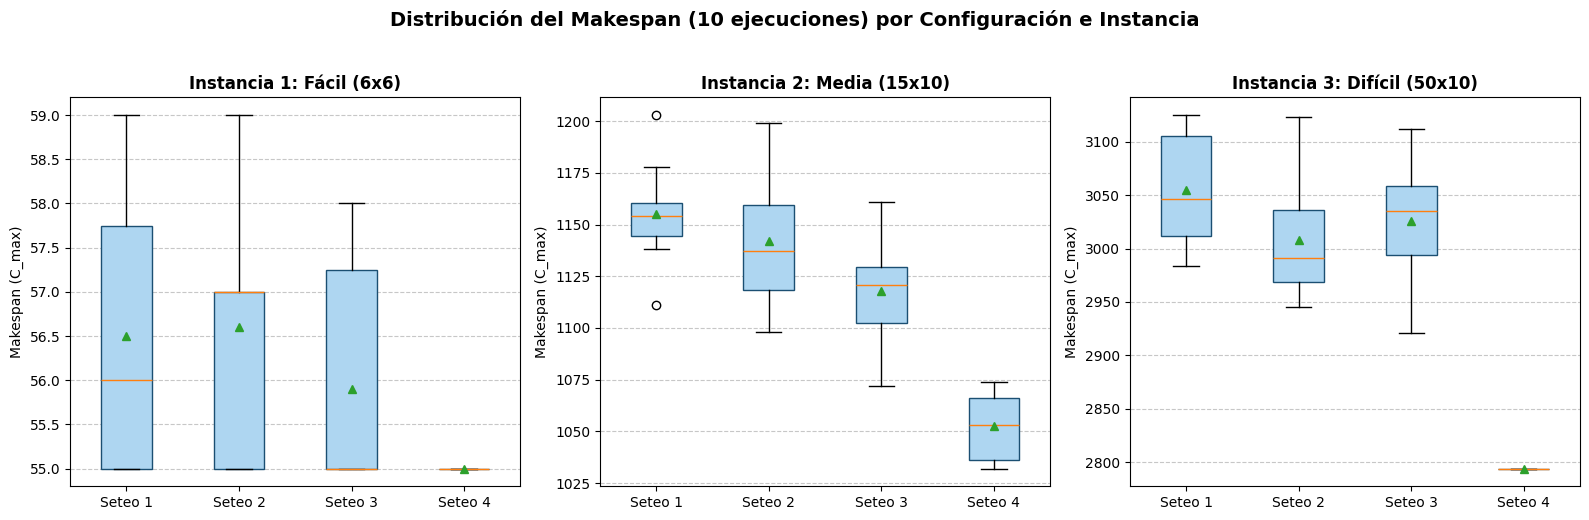

In [ ]:
# Generación de Gráficos de Cajas (Boxplots)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titulos = {
    "01_facil.txt": "Instancia 1: Fácil (6x6)",
    "02_medio.txt": "Instancia 2: Media (15x10)",
    "03_dificil.txt": "Instancia 3: Difícil (50x10)"
}

for idx, archivo in enumerate(["01_facil.txt", "02_medio.txt", "03_dificil.txt"]):
    if archivo in resultados_tuning_boxplot and resultados_tuning_boxplot[archivo]:
        datos_dict = resultados_tuning_boxplot[archivo]
        etiquetas = list(datos_dict.keys())
        valores = list(datos_dict.values())

        bp = axes[idx].boxplot(valores, tick_labels=etiquetas, patch_artist=True, showmeans=True)
        for patch in bp['boxes']:
            patch.set_facecolor('#AED6F1')
            patch.set_edgecolor('#1B4F72')

        axes[idx].set_title(titulos[archivo], fontsize=12, fontweight='bold')
        axes[idx].set_ylabel("Makespan (C_max)")
        axes[idx].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle("Distribución del Makespan (10 ejecuciones) por Configuración e Instancia", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig("boxplots_jsp.png", dpi=300, bbox_inches='tight')
plt.show()

* **Interpretación Visual de los Gráficos de Cajas (*Boxplots*):**
  En las tres gráficas se observa claramente cómo se alcanza el "punto dulce" entre exploración y explotación. En los **Seteos 1, 2 y 3**, la amplia exploración del cruzamiento POX y la Ruleta ubica a la población en zonas competitivas del espacio de búsqueda, pero la naturaleza aleatoria del *Swap* simple produce cajas con mayor dispersión entre cuartiles (mayor variabilidad entre ejecuciones). Al pasar al **Seteo 4**, donde la exploración poblacional se complementa con el refinamiento del individuo élite, las cajas se comprimen y descienden drásticamente hasta colapsar en la cota óptima en las instancias Fácil ($55,00$) y Difícil ($2794,00$) con dispersión nula, demostrando que el equilibrio entre diversificación global e intensificación local es clave a medida que escala la dimensionalidad del problema.

### 6. Conclusiones Experimentales y Análisis de Resultados

* **Efecto de la Sintonización de Parámetros (*Seteo 1 vs. Seteo 2*):** Manteniendo fijo el presupuesto computacional en $\sim 10.000$ evaluaciones, incrementar el porcentaje de elitismo ($10\% \to 20\%$) y la probabilidad de mutación ($0.20 \to 0.35$) acelera la convergencia hacia mejores soluciones en instancias de mayor volumen ($15 \times 10$ y $50 \times 10$), reduciendo tanto el mejor *makespan* como el promedio de las 10 ejecuciones.
* **Impacto del Presupuesto de Evaluaciones (*Seteo 1 vs. Seteo 3*):** Al expandir el límite de generaciones de $200$ ($10.050$ evaluaciones) a $550$ ($27.550$ evaluaciones, equivalente al recorrido de enfriamiento geométrico con $\alpha = 0.9995$ en *Simulated Annealing*), el Algoritmo Genético dispone de más ciclos de recombinación POX para ensamblar bloques libres de tiempos muertos, mejorando la calidad media a cambio de un incremento lineal y controlado en el tiempo de ejecución.
* **Exploración Global (POX) vs. Explotación Fina (*Seteo 4 - Swap Guiado*):** En cromosomas extensos ($500$ operaciones en la instancia difícil), un único *Swap* aleatorio tiene baja probabilidad de acertar justo en la operación crítica que retrasa el sistema. Al incorporar un *Swap* guiado que descarta intercambios perjudiciales, se combina la exploración paralela de la población con el ajuste fino de trayectoria, disminuyendo de forma notable el *makespan* y la desviación estándar entre ejecuciones.